In [ ]:
print("hello from notebook")

hello from notebook


In [1]:
import pandas as pd
data = pd.read_csv("../data/bank.csv", sep=";")

In [ ]:
import os
os.getcwd()

In [ ]:
data.columns
data.dtypes




In [ ]:
data["job"].unique()
data["marital"].unique()
data["education"].unique()
data["default"].unique()
data["housing"].unique()
data["loan"].unique()
data["y"].value_counts()
data["month"].value_counts()


In [ ]:
pd.crosstab(data["job"],data["y"],normalize="index")
pd.crosstab(data["education"], data["y"], normalize="index")
pd.crosstab(data["housing"],data["y"],normalize="index")
pd.crosstab(data["loan"],data["y"], normalize="index")
pd.crosstab(data["contact"],data["y"], normalize= "index")
pd.crosstab(data["month"], data["y"], normalize="index")
pd.crosstab(data["month"],data["y"])
pd.crosstab(data["age"], data["y"], normalize="index")

In [ ]:
data[["age", "balance","duration","campaign","pdays","previous"]].age.max()
data[["age", "balance", "duration", "campaign", "pdays", "previous"]].min()
data[["age", "balance", "duration", "campaign", "pdays", "previous"]].mean()
data[["age", "balance", "duration", "campaign", "pdays", "previous"]].median()
data[["age", "balance", "duration", "campaign", "pdays", "previous"]].std()
data["balance"].describe()
data["age"].describe()
x = data["balance"]>=3462
x.value_counts()

In [ ]:
data.groupby("y")["balance"].mean()
data.groupby("y")["age"].mean()
data.groupby("y")["duration"].mean()
data.groupby("y")["campaign"].mean()


In [ ]:
data.groupby("y")["balance"].median()
data.groupby("y")["age"].median()
data.groupby("y")["duration"].median()
data.groupby("y")["campaign"].median()
data["pdays"].value_counts().head()
data["previous"].value_counts().head(10)

In [ ]:
data["previously_contacted"] = data["pdays"] != -1
pd.crosstab(
    data["previously_contacted"],
    data["y"],
    normalize="index"
)


data["poutcome"].value_counts()
pd.crosstab(
    data["poutcome"],
    data["y"],
    normalize="index"
)
data["poutcome"].describe()


pd.crosstab(
    data["default"],
    data["y"],
    normalize="index"
)


pd.crosstab(
    data["marital"],
    data["y"],
    normalize="index"
)


In [2]:
y = data["y"]
x = data.drop(columns=["duration","y"])
x.shape
x.columns
y.shape

from sklearn.model_selection import train_test_split
x_train, x_temp, y_train, y_temp= train_test_split(
    x,
    y,
    test_size = 0.15,
    random_state = 40,
    stratify=y
)

x_val, x_test, y_val, y_test= train_test_split(
    x_temp,
    y_temp,
    test_size = 0.50,
    random_state = 40,
    stratify=y_temp
)


In [ ]:
print(x_val.shape)
print(x_test.shape)
print(y_val.shape)
print(y_test.shape)

print(y_train.value_counts(normalize=True))
print(y_test.value_counts(normalize=True))
print(y_val.value_counts(normalize=True))
print(y_train.value_counts(normalize=True) * 100)
print(y_val.value_counts(normalize=True) * 100)
print(y_test.value_counts(normalize=True) * 100)


C:\Users\Admin\AppData\Local\Temp\ipykernel_23584\2939313275.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = x_train.select_dtypes(include=["object"]).columns


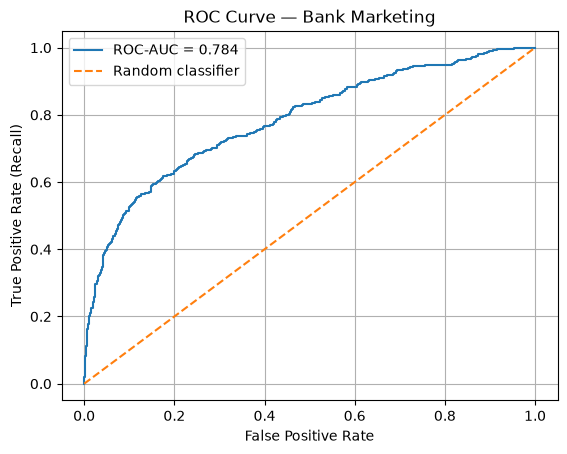

In [3]:
x_train["previously_contacted"] = x_train["pdays"] != -1
x_val["previously_contacted"] = x_val["pdays"] != -1
x_test["previously_contacted"] = x_test["pdays"] != -1
numeric_features = x_train.select_dtypes(include=["int64", "float64"]).columns
categorical_features = x_train.select_dtypes(include=["object"]).columns
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
preprocessor = ColumnTransformer([
    ("num", StandardScaler(),numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)],
    remainder="passthrough")


x_train_processed = preprocessor.fit_transform(x_train)
x_train_processed.shape
x_train.columns.tolist()
"previously_contacted" in x_train.columns

feature_names = preprocessor.get_feature_names_out()
feature_names

x_val_processed = preprocessor.transform(x_val)
x_test_processed = preprocessor.transform(x_test)

x_train_processed.shape, x_val_processed.shape, x_test_processed.shape

preprocessor.named_transformers_["num"].mean_
preprocessor.named_transformers_["num"].scale_
numeric_features
x_train["age"].iloc[0]

preprocessor.named_transformers_["cat"].categories_
preprocessor.named_transformers_["cat"].get_feature_names_out()
x_train.iloc[0][categorical_features]
x_train.iloc[1][categorical_features]


row_1 = x_train_processed[1]
if hasattr(row_1, "toarray"):
    row_1 = row_1.toarray().ravel()
list(zip(feature_names, row_1))


from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=1000)
model.fit(x_train_processed, y_train)
model.coef_
model.intercept_
model.classes_

coefficient_table = list(zip(feature_names, model.coef_[0]))
coefficient_table

y_val_proba = model.predict_proba(x_val_processed)
y_val_proba[:5]

model.predict(x_val_processed)[:10]
y_val[:10]

from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score
from sklearn.metrics import precision_score
from sklearn.metrics import f1_score
y_val_pred = model.predict(x_val_processed)

cm = confusion_matrix(y_val,y_val_pred)
cm

accuracy_score(y_val,y_val_pred)
recall = recall_score(y_val,y_val_pred, pos_label="yes")
precision = precision_score(y_val, y_val_pred, pos_label="yes")
f1 = f1_score(y_val,y_val_pred,pos_label="yes")
recall, precision, f1

y_val_proba[:,1]
y_val_proba.shape

from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    y_val,
    y_val_proba[:, 1]
)
roc_auc

from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_val,
    y_val_proba[:, 1],
    pos_label="yes"
)

plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve — Bank Marketing")
plt.legend()
plt.grid(True)
plt.show()





Precision: 0.5638766519823789
Recall: 0.3224181360201511
F1: 0.41025641025641024
Same probabilities: True
Default recall: 0.19899244332493704
Threshold 0.30 recall: 0.3224181360201511
[[2812  182]
 [ 229  168]]
Precision: 0.48
Recall: 0.42317380352644834
F1: 0.4497991967871486


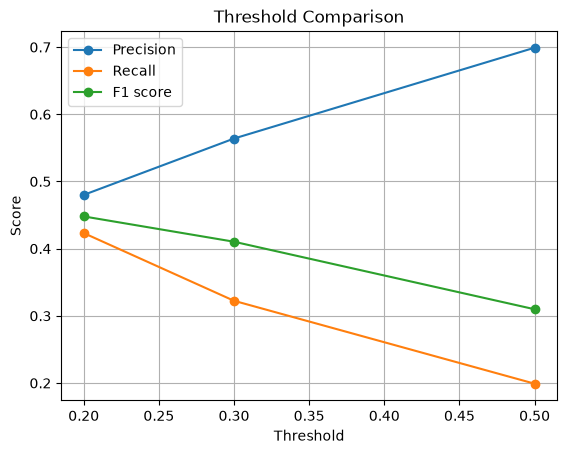

In [4]:
import numpy as np
yes_proba = y_val_proba[:, 1]
threshold = 0.30
y_val_pred_30 = np.where(
    yes_proba >= threshold,
    "yes",
    "no"
)
confusion_matrix(y_val, y_val_pred_30)

accuracy_30 = accuracy_score(y_val, y_val_pred_30)
precision_30 = precision_score(y_val, y_val_pred_30, pos_label="yes")
recall_30 = recall_score(y_val, y_val_pred_30, pos_label="yes")
f1_30 = f1_score(y_val, y_val_pred_30, pos_label="yes")

accuracy_30, precision_30, recall_30, f1_30

print("Precision:", precision_score(y_val, y_val_pred_30, pos_label="yes"))
print("Recall:", recall_score(y_val, y_val_pred_30, pos_label="yes"))
print("F1:", f1_score(y_val, y_val_pred_30, pos_label="yes"))

print("Same probabilities:",
      np.array_equal(yes_proba, y_val_proba[:, 1]))

print("Default recall:",
      recall_score(y_val, model.predict(x_val_processed), pos_label="yes"))

print("Threshold 0.30 recall:",
      recall_score(y_val, y_val_pred_30, pos_label="yes"))

cm

threshold = 0.20

y_val_pred_20 = np.where(
    yes_proba >= threshold,
    "yes",
    "no"
)

print(confusion_matrix(y_val, y_val_pred_20))
print("Precision:", precision_score(y_val, y_val_pred_20, pos_label="yes"))
print("Recall:", recall_score(y_val, y_val_pred_20, pos_label="yes"))
print("F1:", f1_score(y_val, y_val_pred_20, pos_label="yes"))


import matplotlib.pyplot as plt

thresholds = [0.50, 0.30, 0.20]
precisions = [0.6991, 0.5639, 0.4800]
recalls = [0.1990, 0.3224, 0.4232]
f1_scores = [0.3098, 0.4103, 0.4480]

plt.plot(thresholds, precisions, marker="o", label="Precision")
plt.plot(thresholds, recalls, marker="o", label="Recall")
plt.plot(thresholds, f1_scores, marker="o", label="F1 score")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold Comparison")
plt.legend()
plt.grid(True)
plt.show()

In [5]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=40,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(x_train_processed, y_train)
rf_val_pred = rf_model.predict(x_val_processed)

rf_val_proba = rf_model.predict_proba(x_val_processed)
rf_val_proba

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

print("Accuracy:", accuracy_score(y_val, rf_val_pred))
print("Precision:", precision_score(y_val, rf_val_pred, pos_label="yes"))
print("Recall:", recall_score(y_val, rf_val_pred, pos_label="yes"))
print("F1:", f1_score(y_val, rf_val_pred, pos_label="yes"))

from sklearn.metrics import confusion_matrix

confusion_matrix(y_val, rf_val_pred)





Accuracy: 0.8808611029194928
Precision: 0.48936170212765956
Recall: 0.40554156171284633
F1: 0.44352617079889806


array([[2826,  168],
       [ 236,  161]])

In [6]:
rf_yes_proba = rf_val_proba[:, 1]

rf_val_pred_20 = np.where(
    rf_yes_proba >= 0.20,
    "yes",
    "no"
)

print(confusion_matrix(y_val, rf_val_pred_20))
print("Precision:", precision_score(y_val, rf_val_pred_20, pos_label="yes"))
print("Recall:", recall_score(y_val, rf_val_pred_20, pos_label="yes"))
print("F1:", f1_score(y_val, rf_val_pred_20, pos_label="yes"))

[[2117  877]
 [ 100  297]]
Precision: 0.25298126064735943
Recall: 0.7481108312342569
F1: 0.3781031190324634


In [7]:
print("Logistic Regression")
print("Precision:", precision)
print("Recall:", recall)
print("F1:", f1)

print("\nRandom Forest")
print("Precision:", precision_score(y_val, rf_val_pred, pos_label="yes"))
print("Recall:", recall_score(y_val, rf_val_pred, pos_label="yes"))
print("F1:", f1_score(y_val, rf_val_pred, pos_label="yes"))

import pandas as pd

model_comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Precision": [precision, 0.4894],
    "Recall": [recall, 0.4055],
    "F1": [f1, 0.4435]
})

model_comparison

Logistic Regression
Precision: 0.6991150442477876
Recall: 0.19899244332493704
F1: 0.30980392156862746

Random Forest
Precision: 0.48936170212765956
Recall: 0.40554156171284633
F1: 0.44352617079889806


,Model,Precision,Recall,F1
0,Logistic Regression,0.699115,0.198992,0.309804
1,Random Forest,0.489400,0.405500,0.443500


In [8]:
rf_test_pred = rf_model.predict(x_test_processed)

print("Test F1:", f1_score(y_test, rf_test_pred, pos_label="yes"))
print("Test Recall:", recall_score(y_test, rf_test_pred, pos_label="yes"))
print("Test Precision:", precision_score(y_test, rf_test_pred, pos_label="yes"))

Test F1: 0.39727891156462586
Test Recall: 0.3686868686868687
Test Precision: 0.4306784660766962
